In [1]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import utils
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import tensorflow as tf

In [2]:
tf.config.threading.set_inter_op_parallelism_threads(4)
tf.config.threading.set_intra_op_parallelism_threads(4)

from tensorflow.keras.datasets import fashion_mnist
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

train_images = train_images / 255.0
test_images = test_images / 255.0

train_labels_cat = utils.to_categorical(train_labels, 10)
test_labels_cat = utils.to_categorical(test_labels, 10)

train_cnn = train_images.reshape(-1, 28, 28, 1)
test_cnn = test_images.reshape(-1, 28, 28, 1)

val_split = int(len(train_cnn) * 0.85)
X_train, X_val = train_cnn[:val_split], train_cnn[val_split:]
y_train, y_val = train_labels_cat[:val_split], train_labels_cat[val_split:]

datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1
)
datagen.fit(X_train)

In [3]:
model = Sequential([
    Input(shape=(28, 28, 1)),
    
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    
    Flatten(),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(10, activation='softmax')
], name='Optimized_CNN')

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(f"Параметров: {model.count_params():,}")

start = time.time()
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=128),
    epochs=35,
    validation_data=(X_val, y_val),
    steps_per_epoch=len(X_train) // 128,
    verbose=1,
    callbacks=[
        EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True, mode='max'),
        ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=3, verbose=1, mode='max')
    ]
)
training_time = time.time() - start

Параметров: 468,714
Epoch 1/35
398/398 ━━━━━━━━━━━━━━━━━━━━ 201s 476ms/step - accuracy: 0.7245 - loss: 0.7711 - val_accuracy: 0.6289 - val_loss: 1.0748 - learning_rate: 0.0010
Epoch 2/35
  1/398 ━━━━━━━━━━━━━━━━━━━━ 3:41 559ms/step - accuracy: 0.7969 - loss: 0.5011

C:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


398/398 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.7969 - loss: 0.5011 - val_accuracy: 0.6356 - val_loss: 1.0510 - learning_rate: 0.0010
Epoch 3/35
398/398 ━━━━━━━━━━━━━━━━━━━━ 192s 482ms/step - accuracy: 0.8168 - loss: 0.5013 - val_accuracy: 0.8697 - val_loss: 0.3424 - learning_rate: 0.0010
Epoch 4/35
398/398 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.8281 - loss: 0.4236 - val_accuracy: 0.8703 - val_loss: 0.3376 - learning_rate: 0.0010
Epoch 5/35
398/398 ━━━━━━━━━━━━━━━━━━━━ 201s 505ms/step - accuracy: 0.8443 - loss: 0.4293 - val_accuracy: 0.8671 - val_loss: 0.3581 - learning_rate: 0.0010
Epoch 6/35
398/398 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.7734 - loss: 0.6404 - val_accuracy: 0.8510 - val_loss: 0.3934 - learning_rate: 0.0010
Epoch 7/35
398/398 ━━━━━━━━━━━━━━━━━━━━ 0s 456ms/step - accuracy: 0.8502 - loss: 0.4093
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
398/398 ━━━━━━━━━━━━━━━━━━━━ 193s 486ms/step - accuracy: 0.8553 - loss: 0

In [4]:
test_loss, test_acc = model.evaluate(test_cnn, test_labels_cat, verbose=0)

print("\n" + "=" * 60)
print("ФИНАЛЬНЫЕ РЕЗУЛЬТАТЫ")
print("=" * 60)
print(f"Параметры модели: {model.count_params():,}")
print(f"Время обучения: {training_time:.1f}s ({training_time/60:.1f} мин)")
print(f"Тестовая точность: {test_acc:.4f}")
print("=" * 60)

if test_acc >= 0.90:
    print(f" ОТЛИЧНО! Точность {test_acc:.4f} >= 0.90")
    print(" ЗАДАЧА ВЫПОЛНЕНА!")
else:
    print(f" Точность: {test_acc:.4f}")
    print(f"До цели осталось: {0.90 - test_acc:.4f}")
    print(" Попробуй запустить ещё раз - результат может улучшиться")

print("=" * 60)


ФИНАЛЬНЫЕ РЕЗУЛЬТАТЫ
Параметры модели: 468,714
Время обучения: 2140.7s (35.7 мин)
Тестовая точность: 0.9174
 ОТЛИЧНО! Точность 0.9174 >= 0.90
 ЗАДАЧА ВЫПОЛНЕНА!


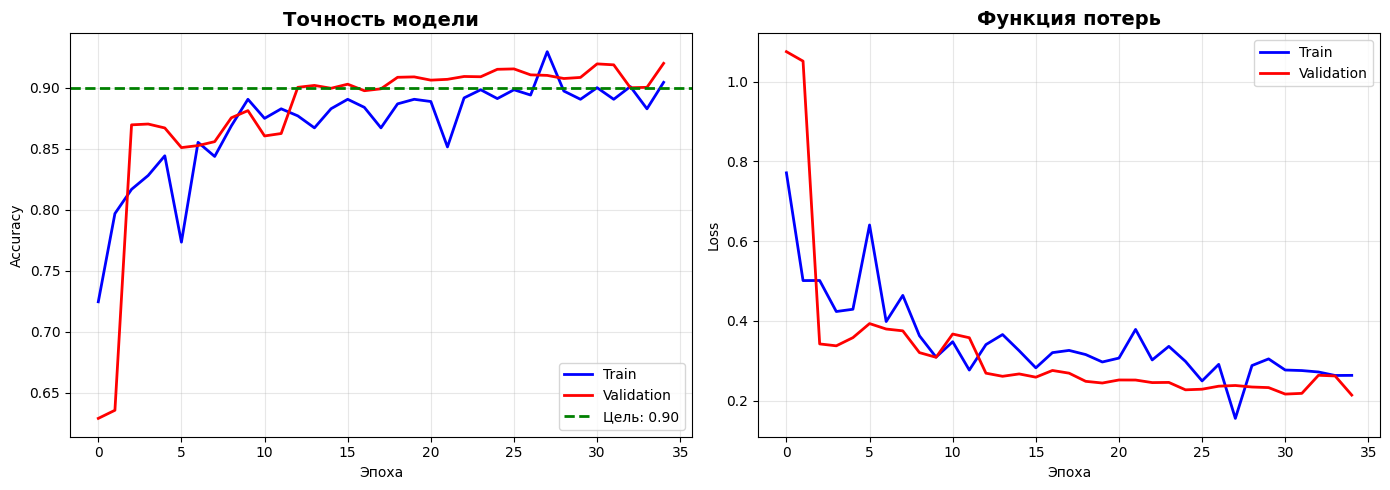

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], 'b-', linewidth=2, label='Train')
axes[0].plot(history.history['val_accuracy'], 'r-', linewidth=2, label='Validation')
axes[0].axhline(y=0.90, color='g', linestyle='--', linewidth=2, label='Цель: 0.90')
axes[0].set_title('Точность модели', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['loss'], 'b-', linewidth=2, label='Train')
axes[1].plot(history.history['val_loss'], 'r-', linewidth=2, label='Validation')
axes[1].set_title('Функция потерь', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
max_val_acc = max(history.history['val_accuracy'])
best_epoch = history.history['val_accuracy'].index(max_val_acc) + 1
print(f"\n Лучшая val_accuracy: {max_val_acc:.4f} на эпохе {best_epoch}")
print(f" Финальная test_accuracy: {test_acc:.4f}")


 Лучшая val_accuracy: 0.9201 на эпохе 35
 Финальная test_accuracy: 0.9174
